# Periodicity Estimation for Star-Planet Interactions

In this notebook we will explore several methods for periodicity extraction -- including the much beloved Lomb-Scargle algorithm, but also the lesser known $Z_n^2$ test and Kuiper's test. 

You will be provided with some basic code, however there will be lines for you to complete yourself following what was covered in the talk. Fear not if you don't remember all of the details from the presentation, there will also be guidance within the markdowns throughout this notebook. 

Happy period hunting! :) 

In [83]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from astropy.stats import kuiper
import scipy.signal as signal


from maser import maser

## Setting up system geometry

We will be using __[Kavanagh's & Vedantham's (2023)](https://github.com/robkavanagh/maser)__ MASER code to simulate visibility curves for radio emission produced by magnetic star-planet interactions. This tool predicts, given a system geometry, the windows during which we will be able to detect these emissions. 

Here I have entered in parameter values which will give us a misaligned system.


In [84]:
rad_per_deg = np.pi / 180

########################################
# Define system parameters
########################################

# Physical constants
sec_per_day = 86400
Msun = 1.989e33
Rsun = 6.955e10
G = 6.674e-8


# Stellar parameters
M_s = 0.2 					# Stellar mass (solar masses)
R_s = 0.3 					# Stellar radius (solar radii)
P_s = 0.8 					# Rotation period (days)
i_s = 73.0 * rad_per_deg    # Stellar inclination (radians)
B_s = 1e3 					# Polar magnetic field strength (Gauss) 
beta = 45.0 * rad_per_deg	# Magnetic obliquity (radians)
phi_s0 = 0.0				# Stellar rotation phase at time zero (0-1)


# Planet parameters
a = 10						# Planet orbital distance (stellar radii)
i_p = 90.0 * rad_per_deg    # Planet orbital inclination (radians)
lam = 0.0 * rad_per_deg		# Projected spin-orbit angle (radians)
phi_p0 = 0.0 				# Planet orbital phase at time zero (0-1)
P_p = 2*np.pi * ((a * R_s * Rsun) ** 3 / (G * M_s * Msun)) ** 0.5 / sec_per_day  # Planet orbital period (days)
P_syn = 1 / abs(1/P_p - 1/P_s) # Synodic period (days)


# Emission parameters
f = 100						# Observing frequency (MHz)
alpha = 75 * rad_per_deg 	# Emission cone opening angle (radians)
dalpha = 1 * rad_per_deg	# Emission cone thickness (radians)




Next, we define the duration of our simulation (effectively our observing baseline). We want to make sure we have good phase coverage, so I will set the duration of the simulation to be ten times the largest fundamental period in the system (orbital, rotational, or synodic). First, we can print out these periods to see what they are.

In [85]:
periods = [P_p, P_s, P_syn]
print(f"Planet orbital period: {P_p:.2f} days")
print(f"Stellar rotation period: {P_s:.2f} days")
print(f"Synodic period: {P_syn:.2f} days")

# Observing times (days)
times = np.linspace(0, 10*np.max(periods), 100000)

Planet orbital period: 1.35 days
Stellar rotation period: 0.80 days
Synodic period: 1.97 days


### Computing and visualising the light curve

Your first task is to plot the visibility curve. We want to consider the periodicities of emissions stemming from both the northern and southern hemispheres. We are also interested in how emissions from each hemisphere may interact to cancel (or not), and how seeing emission from both impacts the periodicities extracted.

In [86]:
# Calling MASER

params = M_s, R_s, P_s, i_s, B_s, beta, phi_s0, a, i_p, lam, phi_p0, f, alpha, dalpha
N, S = maser(params, times)
N = N.astype(int)
S = S.astype(int)


In [87]:
# combine the emissions from N and S (destructively) 

C = N+S
C[C > 1] = 0

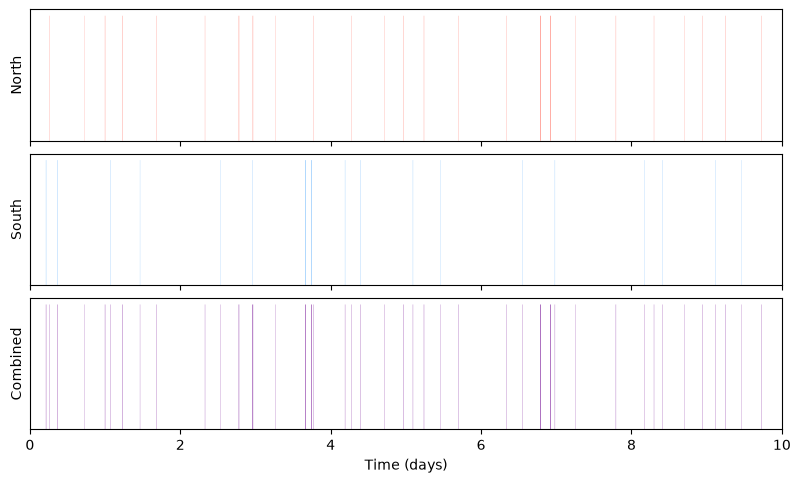

In [88]:
# plot the resulting visbility curves for N, S, and C (combined)

fig, (ax_N, ax_S, ax_C) = plt.subplots(3, sharex = True, figsize = (8, 6))

for ax in [ax_N, ax_S, ax_C]:
	ax.set_ylim(0, 1)
	ax.set_yticks([])

ax_N.set_ylabel('North')
ax_S.set_ylabel('South')
ax_C.set_ylabel('Combined')
ax_C.set_xlabel('Time (days)')

dt = times[1] - times[0]
edges = np.append(times - 0.5 * dt, times[-1] + 0.5 * dt)

ax_N.stairs(N, edges, ec = None, fc = 'xkcd:salmon', fill = True)
ax_N.set_xlim(0,10)
ax_N.set_ylim(0,1.05)

ax_S.stairs(S, edges, ec = None, fc = 'xkcd:sky blue', fill = True)
ax_S.set_xlim(0,10)
ax_S.set_ylim(0,1.05)


ax_C.stairs(C, edges, ec = None, fc = 'xkcd:purple', fill = True)
ax_C.set_xlim(0,10)
ax_C.set_ylim(0,1.05)

plt.subplots_adjust(left = 0.04, right = 0.98, bottom = 0.25, top = 0.95, hspace = 0.1)

plt.show()





### Extracting periodicities

We will now use Lomb-Scargle, the $Z_n^2$ test, and Kuiper's test to determine the periodicity of the emissions from this system. 

#### Provided functions

In the below cell, I provide you with two complete functions: one which computes the period grid that will be input into each algorithm and one which determines the "event" times of the emissions (since the $Z_n^2$ test and Kuiper's test take only event times and not the full time series).

In [89]:
def period_grid(times, star_period, planet_period, synodic_period, oversampling_factor=10):
    baseline = times.max() - times.min()
    if baseline <= 0: return None

    median_resolution = np.median(np.diff(times))
    if median_resolution <= 0: return None

    max_period = baseline/2

    min_period_phys = np.min([star_period, planet_period, synodic_period])/6
    min_period_sampling = 2*median_resolution
    min_period = np.max([min_period_phys, min_period_sampling])

    dp = min_period**2/(oversampling_factor*baseline)
    N_steps = int((max_period - min_period) / dp)

    period_grid = np.linspace(min_period, max_period, N_steps)

    if period_grid[0] <= 0 or np.any(np.diff(period_grid) <= 0): return None
        
    return period_grid



def pulse_centres(times, visibility):
    visibility = np.asarray(visibility)

    # Indices where visibility == 1
    pulse_idx = np.where(visibility > 0)[0]

    if len(pulse_idx) == 0:
        return np.array([])

    # Find breaks between consecutive pulse samples
    breaks = np.where(np.diff(pulse_idx) > 1)[0]

    # Split into contiguous pulse segments
    segments = np.split(pulse_idx, breaks + 1)

    centres = []
    for seg in segments:
        start = seg[0]
        end = seg[-1]
        centres.append(0.5 * (times[start] + times[end]))

    return np.array(centres)



    


In [90]:
# period grid
periods = period_grid(times, P_s, P_p, P_syn)

pulse_times_N = pulse_centres(times, N)
pulse_times_S = pulse_centres(times, S)
pulse_times_C = pulse_centres(times, C)

#### Constructing a Lomb-Scargle periodogram


In [91]:
# function for runnning LS
def run_ls(times, visibility, periods):

    frequencies = 1/periods

    ls = LombScargle(times, visibility)
    data_power = ls.power(frequencies) 

    return data_power


# running LS on N, S, and C (combined)
ls_power_N = run_ls(times, N, periods)
ls_power_S = run_ls(times, S, periods)
ls_power_C = run_ls(times, C, periods)





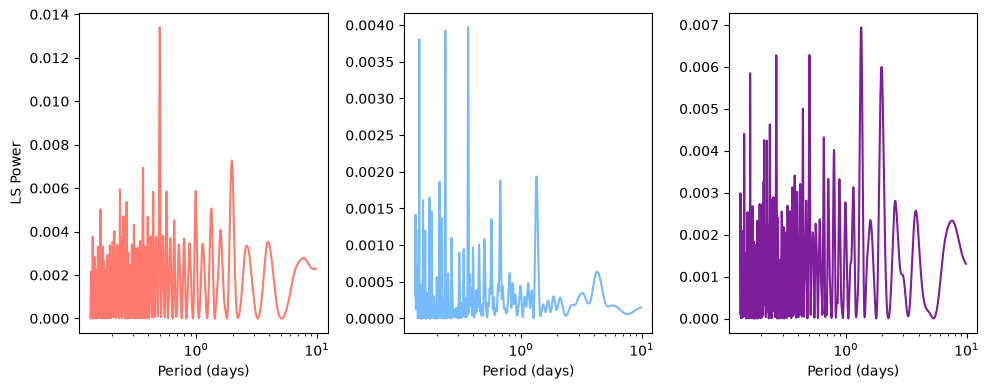

In [92]:
# plot the resulting visbility curves for N, S, and C (combined)
fig, (ax_N, ax_S, ax_C) = plt.subplots(1, 3, figsize = (10, 4))

ax_N.set_ylabel('LS Power')
ax_N.set_xlabel('Period (days)')
ax_S.set_xlabel('Period (days)')
ax_C.set_xlabel('Period (days)')

ax_N.semilogx(periods, ls_power_N, color = 'xkcd:salmon')
ax_S.semilogx(periods, ls_power_S, color = 'xkcd:sky blue')
ax_C.semilogx(periods, ls_power_C, color = 'xkcd:purple')

plt.tight_layout()
plt.show()


#### Constructing a $Z_n^2$ test periodogram

Maximum harmonic set by: $n = 1/(1.7\delta)$

In [93]:

def run_zn2(pulse_times, visibility, periods, max_harmonic):
    Z = np.zeros(len(periods))

    # phase fold the pulse times
    for i, P in enumerate(periods):
        phi = (pulse_times / P) % 1
        theta = 2*np.pi*phi

        # compute the Z^2_n statistic
        z = 0
        for k in range(1, max_harmonic+1):
            C = np.sum(np.cos(k*theta))
            S = np.sum(np.sin(k*theta))
            z += C**2 + S**2
        Z[i] = 2*z/len(phi)
    return Z


times_on_N = times[N > 0]
times_on_S = times[S > 0]
times_on_C = times[C > 0]

max_harmonic_N = 1/(1.7*len(times_on_N)/len(times))
max_harmonic_S = 1/(1.7*len(times_on_S)/len(times))
max_harmonic_C = 1/(1.7*len(times_on_C)/len(times))


# running Z test on N, S, and C (combined)
zn2_power_N = run_zn2(pulse_times_N, N, periods, int(max_harmonic_N))
zn2_power_S = run_zn2(pulse_times_S, S, periods, int(max_harmonic_S))
zn2_power_C = run_zn2(pulse_times_C, C, periods, int(max_harmonic_C))



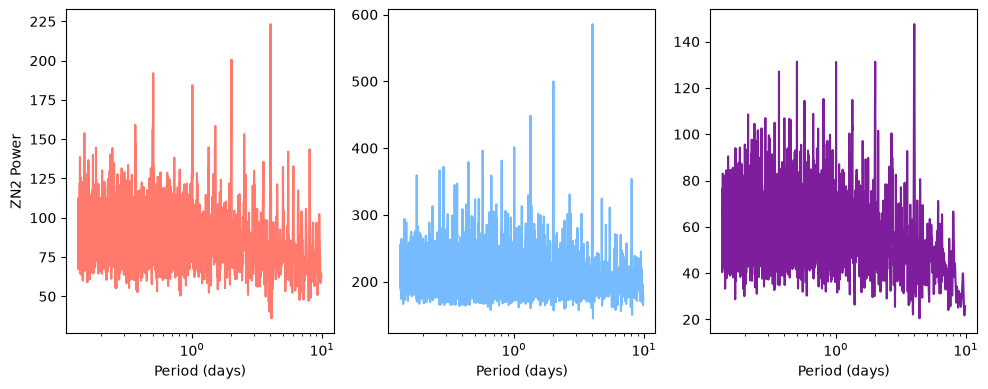

In [94]:
# plot the resulting visbility curves for N, S, and C (combined)
fig, (ax_N, ax_S, ax_C) = plt.subplots(1, 3, figsize = (10, 4))

ax_N.set_ylabel('ZN2 Power')
ax_N.set_xlabel('Period (days)')
ax_S.set_xlabel('Period (days)')
ax_C.set_xlabel('Period (days)')

ax_N.semilogx(periods, zn2_power_N, color = 'xkcd:salmon')
ax_S.semilogx(periods, zn2_power_S, color = 'xkcd:sky blue')
ax_C.semilogx(periods, zn2_power_C, color = 'xkcd:purple')

plt.tight_layout()
plt.show()


#### Constructing a Kuiper's test periodogram


In [95]:
def run_kuiper(pulse_times, visibility, periods):
    if len(pulse_times) < 5:
        return None

    D_scores = []

    for T in periods:
        phases = (pulse_times / T) % 1
        D, _ = kuiper(phases)
        D_scores.append(D)

    return np.asarray(D_scores)


kuiper_power_N = run_kuiper(pulse_times_N, N, periods)
kuiper_power_S = run_kuiper(pulse_times_S, S, periods)
kuiper_power_C = run_kuiper(pulse_times_C, C, periods)

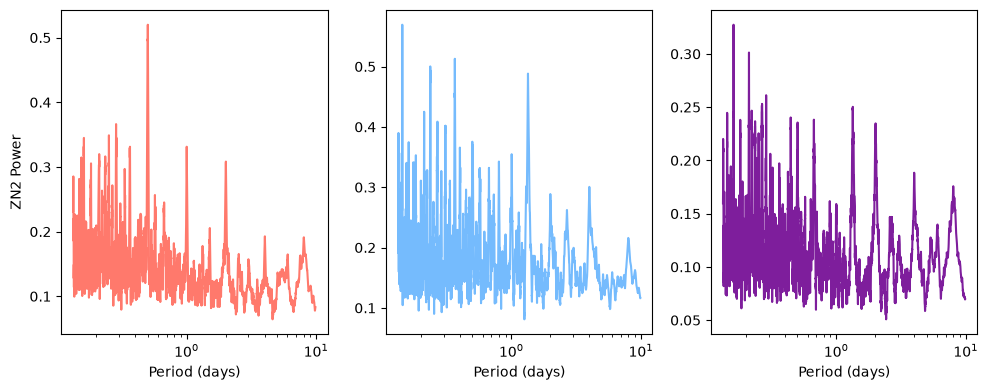

In [96]:
# plot the resulting visbility curves for N, S, and C (combined)
fig, (ax_N, ax_S, ax_C) = plt.subplots(1, 3, figsize = (10, 4))

ax_N.set_ylabel('ZN2 Power')
ax_N.set_xlabel('Period (days)')
ax_S.set_xlabel('Period (days)')
ax_C.set_xlabel('Period (days)')

ax_N.semilogx(periods, kuiper_power_N, color = 'xkcd:salmon')
ax_S.semilogx(periods, kuiper_power_S, color = 'xkcd:sky blue')
ax_C.semilogx(periods, kuiper_power_C, color = 'xkcd:purple')

plt.tight_layout()
plt.show()


### Extract the six most dominant peaks from each periodogram

In [97]:
def locate_peak_periods(power_func, periods, num_peaks, prominence_frac=0.2): 
    
    top_powers = np.full(num_peaks, np.nan)
    top_periods = np.full(num_peaks, np.nan)
    FWHM = np.full(num_peaks, np.nan)

    power_func = np.asarray(power_func, dtype=float)
    periods = np.asarray(periods, dtype=float)

    prom_min = prominence_frac * (np.nanmax(power_func) - np.nanmin(power_func))

    peak_idx, _ = signal.find_peaks(power_func, prominence=prom_min)
    if len(peak_idx) == 0: return top_powers, top_periods, FWHM

    n = min(len(peak_idx), num_peaks)
    candidate_powers = power_func[peak_idx]
    candidate_periods = periods[peak_idx]
    ordered_idx = np.argsort(candidate_powers)[::-1][:n]

    top_powers[:n] = candidate_powers[ordered_idx]
    top_periods[:n] = candidate_periods[ordered_idx]

    dp = periods[1] - periods[0]
    widths = signal.peak_widths(power_func, peak_idx[ordered_idx], rel_height=0.5)[0]*dp 
    FWHM[:n] = widths

    return top_powers, top_periods, FWHM


LS_N_powers, LS_N_periods, LS_N_FWHM = locate_peak_periods(ls_power_N, periods, num_peaks=6)
LS_S_powers, LS_S_periods, LS_S_FWHM = locate_peak_periods(ls_power_S, periods, num_peaks=6)
LS_C_powers, LS_C_periods, LS_C_FWHM = locate_peak_periods(ls_power_C, periods, num_peaks=6)
print("Top 6 LS peaks for N (d):", LS_N_periods)
print("Top 6 LS peaks for S (d):", LS_S_periods)
print("Top 6 LS peaks for C (d):", LS_C_periods)
print('')

z_N_powers, z_N_periods, z_N_FWHM = locate_peak_periods(zn2_power_N, periods, num_peaks=6)
z_S_powers, z_S_periods, z_S_FWHM = locate_peak_periods(zn2_power_S, periods, num_peaks=6)
z_C_powers, z_C_periods, z_C_FWHM = locate_peak_periods(zn2_power_C, periods, num_peaks=6)
print("Top 6 Z peaks for N (d):", z_N_periods)
print("Top 6 Z peaks for S (d):", z_S_periods)
print("Top 6 Z peaks for C (d):", z_C_periods)
print('')


k_N_powers, k_N_periods, k_N_FWHM = locate_peak_periods(kuiper_power_N, periods, num_peaks=6)
k_S_powers, k_S_periods, k_S_FWHM = locate_peak_periods(kuiper_power_S, periods, num_peaks=6)
k_C_powers, k_C_periods, k_C_FWHM = locate_peak_periods(kuiper_power_C, periods, num_peaks=6)
print("Top 6 K peaks for N (d):", k_N_periods)
print("Top 6 K peaks for S (d):", k_S_periods)
print("Top 6 K peaks for C (d):", k_C_periods)
print('')

Top 6 LS peaks for N (d): [0.49951869 1.97443695 0.36280709 0.23411086 0.99169847 0.56796455]
Top 6 LS peaks for S (d): [0.36514866 0.23627231 0.14369027 1.34464496 0.67315504 0.21168583]
Top 6 LS peaks for C (d): [1.33897116 0.49969881 0.26545186 1.97506737 0.16125204 0.44088941]

Top 6 Z peaks for N (d): [4.01403357 2.00974061 0.50240062 1.00520753 0.49987893 0.36568902]
Top 6 Z peaks for S (d): [4.02150858 2.01073127 1.34032207 1.00529759 0.5744489  0.8047332 ]
Top 6 Z peaks for C (d): [4.01547453 0.50258074 2.00983067 1.00493735 0.36568902 0.80482326]

Top 6 K peaks for N (d): [0.50150002 0.28535519 0.25122232 0.16098186 1.00133493 0.36541884]
Top 6 K peaks for S (d): [0.14360021 0.36532878 0.23609219 1.34077237 0.21177589 0.26824373]
Top 6 K peaks for C (d): [0.1608918  0.21168583 0.28724646 0.26707294 1.34077237 0.22222289]



### Why do N, S, and C differ?

THINGS TO CONSIDER --- SPIN-ORBIT, DUTY CYCLE

Northern duty cycle is: 1.2959999999999998
Number of pulses from north: 1296
Southern duty cycle is: 0.5599999999999999
Number of pulses from south: 560
Combined duty cycle is: 1.856
Number of pulses combined: 1856


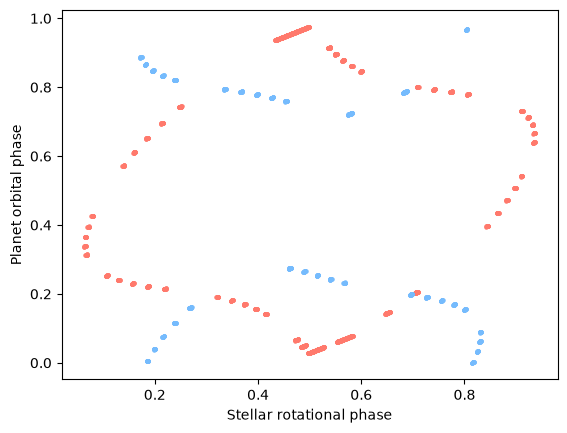

In [98]:
times_on_N = times[N==1]
N_planet_phase = (times_on_N/P_p) % 1
N_star_phase = (times_on_N/P_s) % 1

duty_cycle_N = (len(times_on_N)/len(times))*100
print('Northern duty cycle is:', duty_cycle_N)
print('Number of pulses from north:', len(times_on_N))

times_on_S = times[S==1]
S_planet_phase = (times_on_S/P_p) % 1
S_star_phase = (times_on_S/P_s) % 1

duty_cycle_S = (len(times_on_S)/len(times))*100
print('Southern duty cycle is:', duty_cycle_S)
print('Number of pulses from south:', len(times_on_S))

times_on_C = times[C==1]
C_planet_phase = (times_on_C/P_p) % 1
C_star_phase = (times_on_C/P_s) % 1

duty_cycle_C = (len(times_on_C)/len(times))*100
print('Combined duty cycle is:', duty_cycle_C)
print('Number of pulses combined:', len(times_on_C))



plt.scatter(N_star_phase, N_planet_phase, marker='.', c='xkcd:salmon', s=20, rasterized=True)
plt.scatter(S_star_phase, S_planet_phase, marker='.', c='xkcd:sky blue', s=20, rasterized=True)
plt.xlabel('Stellar rotational phase')
plt.ylabel('Planet orbital phase')
plt.show()


### Compare top six periods to known periods in the system

In [102]:
def combined_periods(p1, p2, max_harm):
    valid = []
    for n in range(-max_harm, max_harm+1):
        for m in range(-max_harm, max_harm+1):
            if n == 0 and m == 0: continue
            freq = n/p1 + m/p2
            if freq == 0: continue 
            valid.append(np.abs(1/freq))
    return valid


def harmonics(p, max_harm):
    harms = []
    for n in range(2, max_harm+1):
        harms.append(p/n)
        harms.append(p*n)

    return harms


star_harmonics = harmonics(P_s, max_harm=6)
planet_harmonics = harmonics(P_p, max_harm=6)
synodic_harmonics = harmonics(P_syn, max_harm=6)
combined = combined_periods(P_s, P_p, max_harm=3)


star_harmonics.append(P_s)
planet_harmonics.append(P_p)
synodic_harmonics.append(P_syn)

p = LS_N_periods
tolerances = LS_N_FWHM

for i in range(len(p)):
    if abs(p[i] - P_p) < tolerances[i]/2:
        print('Peak', {i+1}, 'is planet')
# else: print('It is not planet')
    for harm in planet_harmonics:
        if abs(p[i] - harm) < tolerances[i]/2:
            print('Peak', {i+1}, 'is planet harmonic:', harm)
    # else: print('It is not planet harmonic')

for i in range(len(p)):
    if abs(p[i] - P_s) < tolerances[i]/2:
        print('Peak', {i+1}, 'is star')
# else: print('It is not planet')
    for harm in star_harmonics:
        if abs(p[i] - harm) < tolerances[i]/2:
            print('Peak', {i+1}, 'is star harmonic:', harm)


for i in range(len(p)):
    if abs(p[i] - P_syn) < tolerances[i]/2:
        print('Peak', {i+1}, 'is synodic')
# else: print('It is not planet')
    for harm in synodic_harmonics:
        if abs(p[i] - harm) < tolerances[i]/2:
            print('Peak', {i+1}, 'is synodic harmonic:', harm)


for i in range(len(p)):
    for c in combined:
        if abs(p[i] - c) < tolerances[i]/2:
            print('Peak', {i+1}, 'is combined')


Peak {1} is synodic harmonic: 0.4935013665968063
Peak {2} is synodic
Peak {2} is synodic harmonic: 1.9740054663872253
Peak {5} is synodic harmonic: 0.9870027331936126
Peak {1} is combined
Peak {1} is combined
Peak {2} is combined
Peak {2} is combined
Peak {3} is combined
Peak {3} is combined
Peak {5} is combined
Peak {5} is combined
Peak {6} is combined
Peak {6} is combined


### Phase folding

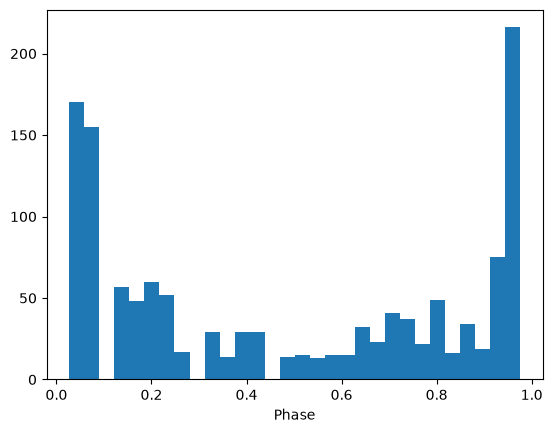

In [103]:

## for example folding on the planet period

folded = (times_on_N / P_p) % 1

plt.hist(folded, bins=30)
plt.xlabel('Phase')
plt.show()


## The effects of your window function

In [104]:

# Random sinusoidal light curve with realistic observing gaps and a daily systematic.
def make_light_curve(
    seed=None,
    t_span=30.0,             # total baseline [days]
    cadence=10.0 / 1440,     # cadence [days] (10 min)
    period_range=(0.3, 3.0),  # true period drawn log-uniformly from this [days]
    amp_range=(0.5, 2.0),    # true amplitude [arbitrary flux units]
    noise=0.5,               # per-point Gaussian noise sigma
    daily_amp=1.0,           # amplitude of a 1-day systematic (0 to switch off)
    night_window=0.4,        # observable fraction of each day (0.4 d ~ 9.6 h)
    window_jitter=0.03,      # nightly start-time jitter [days]
    weather_loss=0.25,       # probability a whole night is lost
    big_gap=(3.0, 5.0),      # (min, max) length of one long outage [days], or None
    dropout=0.02,            # fraction of random individual points lost
):
    rng = np.random.default_rng(seed)

    # --- true signal ---
    period = np.exp(rng.uniform(np.log(period_range[0]), np.log(period_range[1])))
    amp = rng.uniform(*amp_range)
    phase = rng.uniform(0, 2 * np.pi)
    offset = rng.uniform(-1, 1)

    # --- daily systematic (e.g. airmass / scattered light): exactly 1 d period ---
    daily_phase = rng.uniform(0, 2 * np.pi)

    # --- ideal, evenly sampled time grid ---
    t = np.arange(0, t_span, cadence)

    # --- observing gaps ---
    keep = np.zeros_like(t, dtype=bool)

    # 1. Nightly window: only observe for `night_window` days each day
    for night in range(int(np.ceil(t_span))):
        start = night + rng.normal(0, window_jitter)
        in_window = (t >= start) & (t < start + night_window)
        # 2. Weather: lose some entire nights
        if rng.random() > weather_loss:
            keep |= in_window

    # 3. One long outage (instrument failure, telescope time swap, etc.)
    if big_gap is not None:
        gap_len = rng.uniform(*big_gap)
        gap_start = rng.uniform(0.2 * t_span, 0.8 * t_span - gap_len)
        keep &= ~((t >= gap_start) & (t < gap_start + gap_len))

    # 4. Random single-point dropouts
    keep &= rng.random(t.size) > dropout

    t = t[keep]

    # --- observed flux ---
    y = offset + amp * np.sin(2 * np.pi * t / period + phase)
    y += daily_amp * np.sin(2 * np.pi * t / 1.0 + daily_phase)
    y += rng.normal(0, noise, t.size)
    dy = np.full_like(t, noise)

    truth = dict(period=period, freq=1 / period, amp=amp, phase=phase,
                 offset=offset, noise=noise,
                 daily_freq=1.0, daily_amp=daily_amp)
    return t, y, dy, truth



In [105]:
t, y, dy, truth = make_light_curve(seed=42, t_span=30, weather_loss=0, big_gap=None)

print(f"{t.size} points, true period = {truth['period']:.3f} d "
          f"(f = {truth['freq']:.3f} /d), amp = {truth['amp']:.2f}")

1694 points, true period = 1.783 d (f = 0.561 /d), amp = 1.16


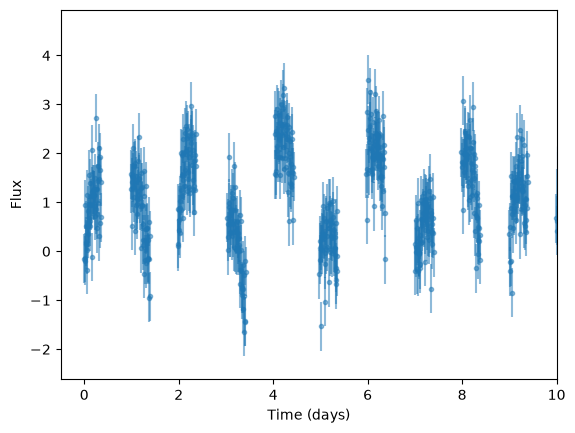

In [106]:
plt.errorbar(t, y, dy, fmt=".", ms=6, alpha=0.5, rasterized=True)
plt.xlabel('Time (days)')
plt.xlim(-0.5,10)
plt.ylabel('Flux')
plt.show()

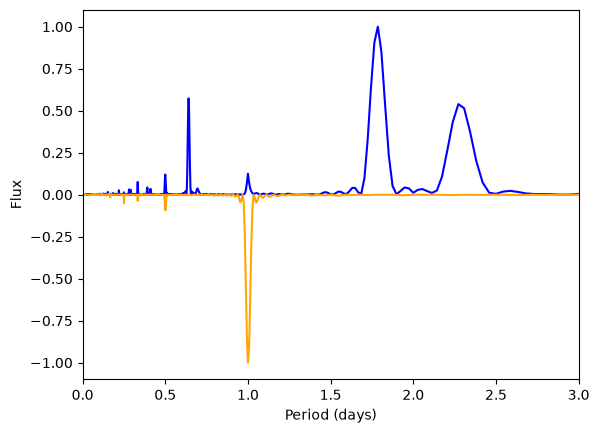

In [107]:
baseline =30
fmin = 3/baseline

avg_temp_res = np.median(np.diff(t))
fmax = 1/(2*avg_temp_res)

oversampling_factor = 5
f_step = 1/(oversampling_factor*baseline)

frequencies = np.arange(fmin, fmax, f_step)
frequencies_window = np.arange(0, fmax, f_step)

power = LombScargle(t, y, dy).power(frequencies)


window_power = []
for f in frequencies:
    W = np.sum(np.exp(-2j*np.pi*f*t))
    window_power.append(np.abs(W)**2/len(t)**2 )

window_power = np.array(window_power)

plt.plot(1/frequencies, power/power.max(), c='blue')
plt.plot(1/frequencies, -window_power/window_power.max(), c='orange')
plt.xlabel('Period (days)')
plt.ylabel('Flux')
plt.xlim(0,3)
plt.show()

